In [1]:
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt
import seaborn as sns
import random
import types

from time import time

from scipy.special import comb, loggamma, lambertw
from scipy.stats import multinomial, expon

from silence_tensorflow import silence_tensorflow
silence_tensorflow()
import tensorflow as tf
import tensorflow_probability as tfp
from tensorflow import keras
from tensorflow.keras import optimizers, initializers, regularizers, layers

config = tf.compat.v1.ConfigProto()
config.gpu_options.allow_growth = True
sess = tf.compat.v1.Session(config = config)

import os, shutil
from pathlib import Path
import json
import subprocess

import lifelines
from lifelines.utils import concordance_index
from lifelines.statistics import logrank_test

import sys
sys.path.insert(0, "../src")
from package import cure_aft
from package import gndr_utils as utils

import thetaflow as thf

E0000 00:00:1793686938.904511   71202 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1793686938.909383   71202 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1793686938.922507   71202 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1793686938.922532   71202 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1793686938.922534   71202 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1793686938.922535   71202 computation_placer.cc:177] computation placer already registered. Please check linka

In this notebook, we explore the results for the AFT cure rate models assuming
\begin{align*}
    \mu &=  \mathcal{F}_1(\boldsymbol x_i ; \boldsymbol \omega)\\
    \sigma &= \boldsymbol z_\sigma^\top \boldsymbol \beta_\sigma\\
    p &= \mathcal{F}_2(\boldsymbol x_i ; \boldsymbol \omega)
\end{align*}

In [2]:
df_clean_train = pd.read_csv("../data/00_clean/metabric_train_data.csv")
df_clean_test = pd.read_csv("../data/00_clean/metabric_test_data.csv")

df_train = pd.read_csv("../data/01_mlready/metabric_train.csv")
df_test = pd.read_csv("../data/01_mlready/metabric_test.csv")

print("Train data dimension: {}".format(df_train.shape))
print("Test data dimension: {}".format(df_test.shape))

df_train.head()

Train data dimension: (1386, 183)
Test data dimension: (463, 183)


,patient_id,time,delta,age_at_diagnosis,npi,pam50_subtype_Basal,pam50_subtype_Her2,pam50_subtype_LumB,pam50_subtype_Normal,pam50_subtype_claudin-low,...,NT5E,NRAS,CCND3,AGTR2,MBL2,SIAH1,STMN2,RASGEF1B,SMARCB1,HRAS
0,MB-5223,136.700000,1.0,-1.472877,-0.016511,0.0,0.0,0.0,0.0,1.0,...,0,0,0,0,0,0,0,0,0,0
1,MB-5576,194.000000,0.0,0.497740,-0.020040,0.0,0.0,1.0,0.0,0.0,...,0,0,0,0,0,0,0,0,0,0
2,MB-6238,172.966667,1.0,1.805360,-0.886508,0.0,0.0,0.0,0.0,0.0,...,0,0,0,0,0,0,0,0,0,0
3,MB-0379,119.500000,1.0,-1.000511,-0.004158,0.0,0.0,0.0,0.0,0.0,...,0,0,0,0,0,0,0,0,0,0
4,MB-4708,18.700000,1.0,0.133321,-0.023570,0.0,0.0,0.0,0.0,0.0,...,0,0,0,0,0,0,0,0,0,0


In [3]:
# Lifetimes and censoring indicators
y_train = df_train["time"] / 12
delta_train = df_train["delta"]
# Data for the neural network interpreter
X_train_nn = df_train.iloc[:, 3:]
z_train_sigma = df_train.iloc[:, 5:10]
z_train_sigma.insert(0, "const", 1)

# Lifetimes and censoring indicators
y_test = df_test["time"] / 12
delta_test = df_test["delta"]
# Data for the neural network interpreter
X_test_nn = df_test.iloc[:, 3:]
z_test_sigma = df_test.iloc[:, 5:10]
z_test_sigma.insert(0, "const", 1)

In [4]:
wb_parameters, wb_loss, wb_survival_cure = cure_aft.build_cure_aft_structure5("wb", z_train_sigma)
ln_parameters, ln_loss, ln_survival_cure = cure_aft.build_cure_aft_structure5("ln", z_train_sigma)
ll_parameters, ll_loss, ll_survival_cure = cure_aft.build_cure_aft_structure5("ll", z_train_sigma)

data_train = [z_train_sigma, y_train, delta_train]
data_test = [z_test_sigma, y_test, delta_test]

In [5]:
wb_model = cure_aft.train_model( wb_parameters, wb_loss, cure_aft.neural_network2, cure_aft.network_call, cure_aft.network_call_nolast, X_train_nn, data_train )
wb_summary = wb_survival_cure(wb_model,
                              y_train, delta_train, X_train_nn, z_train_sigma,
                              y_test, delta_test, X_test_nn, z_test_sigma, ngrid = 100)

Global seed set to 10.
Initializing training...
Optimizing... Epoch: [ 76 / 15000 ]  | Avg. Train NLL:  1.99156809 | Avg. Validation NLL:  2.14936233 | Best Avg. Validation NLL:  1.98382592 | Speed:  0.0125408294  epoch/s    | Elapsed Time:  0.953103065  s   
Convergence criterion reached. Stopping.
Optimizing... Epoch: [ 77 / 15000 ]  | Avg. Train NLL:  1.99546683 | Avg. Validation NLL:  2.15340137 | Best Avg. Validation NLL:  1.98382592 | Speed:  0.0125356773  epoch/s    | Elapsed Time:  0.965247154  s   Restoring best weights...

Done.
Initializing model fine tuning (only independent parameters and last-layer)
Optimizing... Epoch: [ 4195 / 15000 ]  | Avg. Train NLL:  1.40841162 | Best Avg. Train NLL:  1.40841162 | Avg. Validation NLL:  1.88031578 | Speed:  0.00466110557  epoch/s    | Elapsed Time:  19.5533371  s   
Convergence criterion reached. Stopping.
Restoring best weights...

Done.
Extracting covariance structure.
Done.
Optimization finished in 32.552 seconds.


In [6]:
ln_model = cure_aft.train_model( ln_parameters, ln_loss, cure_aft.neural_network2, cure_aft.network_call, cure_aft.network_call_nolast, X_train_nn, data_train )
ln_summary = ln_survival_cure(ln_model,
                              y_train, delta_train, X_train_nn, z_train_sigma,
                              y_test, delta_test, X_test_nn, z_test_sigma, ngrid = 100)

Global seed set to 10.
Initializing training...
Optimizing... Epoch: [ 61 / 15000 ]  | Avg. Train NLL:  2.08894396 | Avg. Validation NLL:  2.22179604 | Best Avg. Validation NLL:  1.95607734 | Speed:  0.012281727  epoch/s    | Elapsed Time:  0.749185324  s    
Convergence criterion reached. Stopping.
Optimizing... Epoch: [ 62 / 15000 ]  | Avg. Train NLL:  2.0978961 | Avg. Validation NLL:  2.23088646 | Best Avg. Validation NLL:  1.95607734 | Speed:  0.0122637367  epoch/s    | Elapsed Time:  0.760351658  s   Restoring best weights...

Done.
Initializing model fine tuning (only independent parameters and last-layer)
Optimizing... Epoch: [ 4137 / 15000 ]  | Avg. Train NLL:  1.49928153 | Best Avg. Train NLL:  1.49928153 | Avg. Validation NLL:  1.80720747 | Speed:  0.00432014605  epoch/s    | Elapsed Time:  17.8724442  s   
Convergence criterion reached. Stopping.
Restoring best weights...

Done.
Extracting covariance structure.
Done.
Optimization finished in 24.654 seconds.


In [7]:
ll_model = cure_aft.train_model( ll_parameters, ll_loss, cure_aft.neural_network2, cure_aft.network_call, cure_aft.network_call_nolast, X_train_nn, data_train )
ll_summary = ll_survival_cure(ll_model,
                              y_train, delta_train, X_train_nn, z_train_sigma,
                              y_test, delta_test, X_test_nn, z_test_sigma, ngrid = 100)

Global seed set to 10.
Initializing training...
Optimizing... Epoch: [ 61 / 15000 ]  | Avg. Train NLL:  2.40759873 | Avg. Validation NLL:  2.49098563 | Best Avg. Validation NLL:  1.94245219 | Speed:  0.0116973119  epoch/s    | Elapsed Time:  0.713536  s      
Convergence criterion reached. Stopping.
Optimizing... Epoch: [ 62 / 15000 ]  | Avg. Train NLL:  2.41713357 | Avg. Validation NLL:  2.50029731 | Best Avg. Validation NLL:  1.94245219 | Speed:  0.0116906976  epoch/s    | Elapsed Time:  0.724823236  s   Restoring best weights...

Done.
Initializing model fine tuning (only independent parameters and last-layer)
Optimizing... Epoch: [ 3986 / 15000 ]  | Avg. Train NLL:  1.46140158 | Best Avg. Train NLL:  1.46140158 | Avg. Validation NLL:  1.89057148 | Speed:  0.00417024223  epoch/s    | Elapsed Time:  16.6225853  s   
Convergence criterion reached. Stopping.
Restoring best weights...

Done.
Extracting covariance structure.
Done.
Optimization finished in 23.473 seconds.


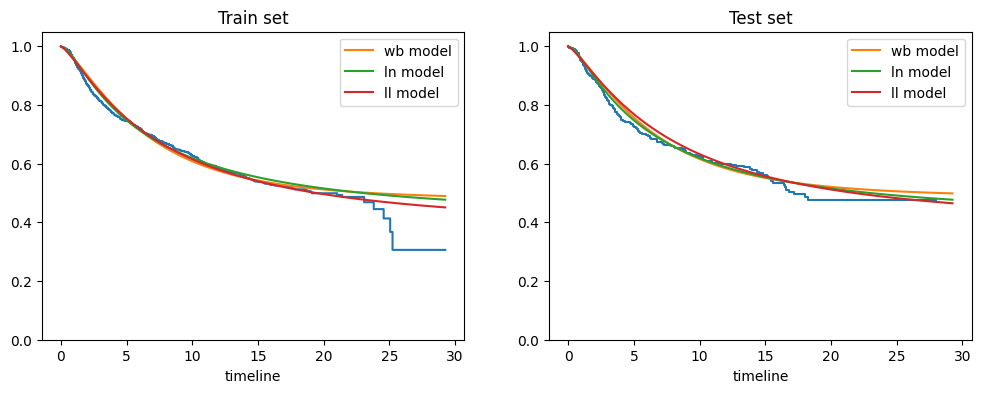

In [8]:
ts_grid = wb_summary["ts_grid"].flatten()

wb_S_ts_train = wb_summary["S_ts_train"]
wb_S_ts_train_avg = np.mean( wb_S_ts_train, axis = 1 )
ln_S_ts_train = ln_summary["S_ts_train"]
ln_S_ts_train_avg = np.mean( ln_S_ts_train, axis = 1 )
ll_S_ts_train = ll_summary["S_ts_train"]
ll_S_ts_train_avg = np.mean( ll_S_ts_train, axis = 1 )

wb_S_ts_test = wb_summary["S_ts_test"]
wb_S_ts_test_avg = np.mean( wb_S_ts_test, axis = 1 )
ln_S_ts_test = ln_summary["S_ts_test"]
ln_S_ts_test_avg = np.mean( ln_S_ts_train, axis = 1 )
ll_S_ts_test = ll_summary["S_ts_test"]
ll_S_ts_test_avg = np.mean( ll_S_ts_test, axis = 1 )

fig, ax = plt.subplots(nrows = 1, ncols = 2, figsize = (12,4))

km_train = lifelines.KaplanMeierFitter()
km_train.fit(y_train, delta_train)
km_train.plot(ax = ax[0], ci_show = False, show_censors = False, legend = False, label = '_')

# for j in range(500):
#     ax[0].plot(ts_grid, wb_S_ts_train[:,j], alpha = 0.05, color = "black")
ax[0].plot(ts_grid, wb_S_ts_train_avg, label = "wb model")
ax[0].plot(ts_grid, ln_S_ts_train_avg, label = "ln model")
ax[0].plot(ts_grid, ll_S_ts_train_avg, label = "ll model")
ax[0].set_ylim(0, 1.05)
ax[0].legend()
ax[0].set_title("Train set")

km_test = lifelines.KaplanMeierFitter()
km_test.fit(y_test, delta_test)
km_test.plot(ax = ax[1], ci_show = False, show_censors = False, legend = False, label = '_')
    
ax[1].plot(ts_grid, wb_S_ts_test_avg, label = "wb model")
ax[1].plot(ts_grid, ln_S_ts_test_avg, label = "ln model")
ax[1].plot(ts_grid, ll_S_ts_test_avg, label = "ll model")
ax[1].set_ylim(0, 1.05)
ax[1].legend()
ax[1].set_title("Test set")

plt.show()

In [11]:
pd.options.display.float_format = '{:.6f}'.format
sigma_colnames = list( np.char.add("sigma_", list(z_train_sigma.columns)) )

colnames = sigma_colnames

display( cure_aft.summary_betas(wb_model, colnames) )

pd.options.display.float_format = None

/home/natan/.pyenv/versions/3.10.17/lib/python3.10/site-packages/thetaflow/modelnn.py:2871: UserWarning: Model supports both neural network modeled parameters and independent parameters.
As a list of input values, x, was not provided, obtaining the covariances only for ['sigma_beta'].
  warnings.warn(


,Coef,Se,Z,pvalue,CI(95%)
sigma_const,-0.429684,0.077918,-5.514589,0.000000,(-0.5824 ; -0.277)
sigma_pam50_subtype_Basal,0.239852,0.144733,1.657199,0.097479,(-0.0438 ; 0.5235)
sigma_pam50_subtype_Her2,0.058193,0.135203,0.430411,0.666896,(-0.2068 ; 0.3232)
sigma_pam50_subtype_LumB,-0.049637,0.110834,-0.447847,0.654264,(-0.2669 ; 0.1676)
sigma_pam50_subtype_Normal,0.068061,0.172274,0.395074,0.692789,(-0.2696 ; 0.4057)
sigma_pam50_subtype_claudin-low,0.273097,0.175431,1.556722,0.119537,(-0.0707 ; 0.6169)


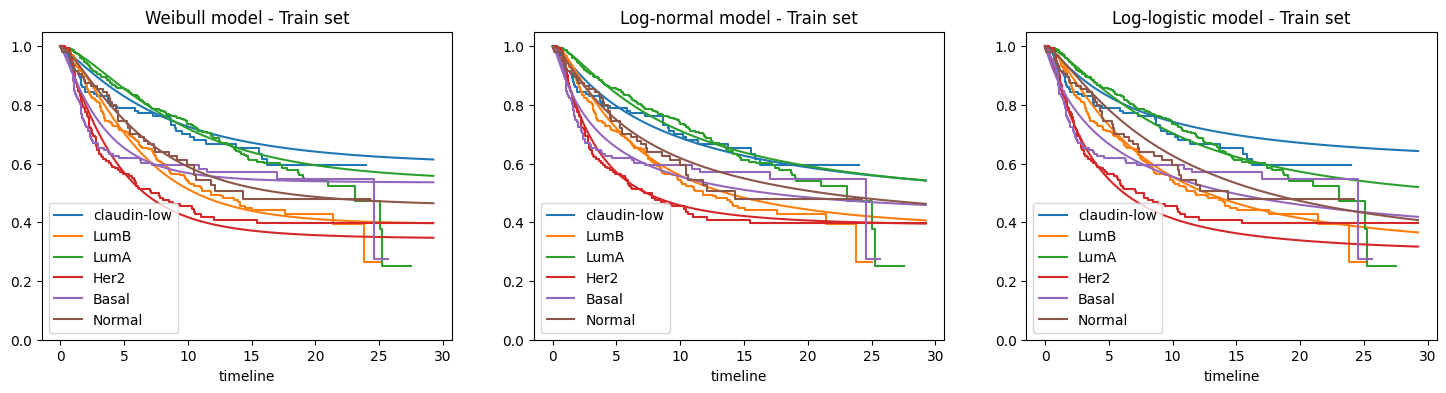

In [12]:
fig, ax = plt.subplots(nrows = 1, ncols = 3, figsize = (18,4))

colors = plt.rcParams['axes.prop_cycle'].by_key()['color']
ts_grid = wb_summary["ts_grid"].flatten()
wb_S_ts_train = wb_summary["S_ts_train"]
ln_S_ts_train = ln_summary["S_ts_train"]
ll_S_ts_train = ll_summary["S_ts_train"]

unique_pam50_subtypes = df_clean_train["pam50_subtype"].unique()

for i, subtype in enumerate(unique_pam50_subtypes):
    subtype_patients = df_clean_train["pam50_subtype"] == subtype
    time = df_clean_train.loc[subtype_patients, "time"] / 12
    delta = df_clean_train.loc[subtype_patients, "delta"]

    wb_S_ts_train_subtype_avg = np.mean(wb_S_ts_train[:, subtype_patients], axis = 1)
    ln_S_ts_train_subtype_avg = np.mean(ln_S_ts_train[:, subtype_patients], axis = 1)
    ll_S_ts_train_subtype_avg = np.mean(ll_S_ts_train[:, subtype_patients], axis = 1)

    ax[0].plot(ts_grid, wb_S_ts_train_subtype_avg, color = colors[i])
    ax[1].plot(ts_grid, ln_S_ts_train_subtype_avg, color = colors[i])
    ax[2].plot(ts_grid, ll_S_ts_train_subtype_avg, color = colors[i])
    
    km = lifelines.KaplanMeierFitter()
    km.fit(time, delta)
    km.plot(ax = ax[0], ci_show = False, show_censors = False, label = subtype)
    km.plot(ax = ax[1], ci_show = False, show_censors = False, label = subtype)
    km.plot(ax = ax[2], ci_show = False, show_censors = False, label = subtype)

ax[0].set_title("Weibull model - Train set")
ax[0].set_ylim(0, 1.05)
ax[1].set_title("Log-normal model - Train set")
ax[1].set_ylim(0, 1.05)
ax[2].set_title("Log-logistic model - Train set")
ax[2].set_ylim(0, 1.05)

plt.show()

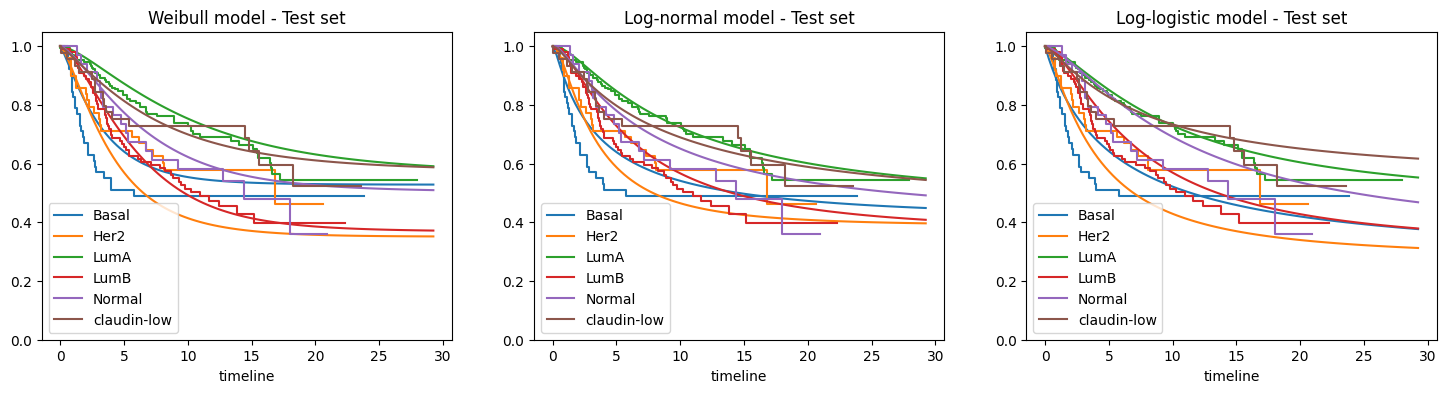

In [13]:
fig, ax = plt.subplots(nrows = 1, ncols = 3, figsize = (18,4))

colors = plt.rcParams['axes.prop_cycle'].by_key()['color']
ts_grid = wb_summary["ts_grid"].flatten()
wb_S_ts_test = wb_summary["S_ts_test"]
ln_S_ts_test = ln_summary["S_ts_test"]
ll_S_ts_test = ll_summary["S_ts_test"]

unique_pam50_subtypes = np.sort( df_clean_train["pam50_subtype"].unique() )

for i, subtype in enumerate(unique_pam50_subtypes):
    subtype_patients = df_clean_test["pam50_subtype"] == subtype
    time = df_clean_test.loc[subtype_patients, "time"] / 12
    delta = df_clean_test.loc[subtype_patients, "delta"]

    wb_S_ts_test_subtype_avg = np.mean(wb_S_ts_test[:, subtype_patients], axis = 1)
    ln_S_ts_test_subtype_avg = np.mean(ln_S_ts_test[:, subtype_patients], axis = 1)
    ll_S_ts_test_subtype_avg = np.mean(ll_S_ts_test[:, subtype_patients], axis = 1)

    ax[0].plot(ts_grid, wb_S_ts_test_subtype_avg, color = colors[i])
    ax[1].plot(ts_grid, ln_S_ts_test_subtype_avg, color = colors[i])
    ax[2].plot(ts_grid, ll_S_ts_test_subtype_avg, color = colors[i])
    
    km = lifelines.KaplanMeierFitter()
    km.fit(time, delta)
    km.plot(ax = ax[0], ci_show = False, show_censors = False, label = subtype)
    km.plot(ax = ax[1], ci_show = False, show_censors = False, label = subtype)
    km.plot(ax = ax[2], ci_show = False, show_censors = False, label = subtype)

ax[0].set_title("Weibull model - Test set")
ax[0].set_ylim(0, 1.05)
ax[1].set_title("Log-normal model - Test set")
ax[1].set_ylim(0, 1.05)
ax[2].set_title("Log-logistic model - Test set")
ax[2].set_ylim(0, 1.05)

plt.show()

In [15]:
wb_model.save_model("../model_weights/Classic Holdout/Structure5/wb_model")
ln_model.save_model("../model_weights/Classic Holdout/Structure5/ln_model")
ll_model.save_model("../model_weights/Classic Holdout/Structure5/ll_model")

Model successfully saved to ../model_weights/Classic Holdout/Structure5/wb_model.weights.h5 and ../model_weights/Classic Holdout/Structure5/wb_model_meta.pkl
Model successfully saved to ../model_weights/Classic Holdout/Structure5/ln_model.weights.h5 and ../model_weights/Classic Holdout/Structure5/ln_model_meta.pkl
Model successfully saved to ../model_weights/Classic Holdout/Structure5/ll_model.weights.h5 and ../model_weights/Classic Holdout/Structure5/ll_model_meta.pkl
